# 45 · 작은 decoder GPT 전체 학습

`gold grape is gold.`를 앞에서부터 읽고 다음 문자를 예측합니다. 44번의 bigram은 마지막 token 하나만 보았습니다. 이번에는 **현재 위치까지의 문맥 전체**를 attention으로 읽고, 모든 층을 직접 미분하여 학습합니다.

- 준비물: [44 토큰 데이터](44_tokenization.ipynb), [09 Transformer](../01_아키텍처/09_transformer.ipynb), [16 정규화](../03_구조조합/16_normalization.ipynb), [04 Adam](../00_기초/04_optimizers.ipynb), [01 중심차분](../00_기초/01_gradients_and_learning.ipynb)입니다.
- 순서: ① 자기회귀 계약 → ② causal attention → ③ 정규화·FFN·전체 backward → ④ 실제 문자 학습 → ⑤ held-out 평가와 자유 생성입니다.
- 범위: 학습 위치 표와 **한 head·한 pre-LN block·tanh FFN·최종 LN**을 사용합니다. 원 GPT의 규모·GELU·다중 head·세부 학습 절차를 재현한 모델이 아닙니다. 외부 pretrained 가중치는 없습니다.

> **용어** · **decoder-only**는 encoder 없이 이전 token들로 다음 token을 예측하는 구조입니다. **pre-LN**은 각 attention/FFN 가지에 들어가기 전에 LayerNorm을 적용하는 배치입니다. **FFN**은 각 token에 같은 두 선형층과 비선형 함수를 적용하는 부분입니다. **prefix**는 이미 주어졌거나 생성한 앞부분입니다.

### 읽는 법

| 표시 | 확인할 것 |
|---|---|
| 🔑 핵심 | 수식·모양·미분 연결 |
| 🔍 확인 | 출력·경계·한계 |
| 📎 참고 | 코드·방법의 범위 |
| ✏️ 연습 | 한두 줄의 재구성 |

**이 노트북에서 반드시 가져갈 세 가지**

1. causal mask는 정답이 보이는 경로를 막고, padding mask는 없는 token을 제외합니다.
2. 전체 backward는 잔차·Q/K/V·정규화·embedding의 모든 공유 경로를 합칩니다.
3. teacher forcing의 token 점수와 정답을 주지 않는 자유 생성은 다른 평가입니다.

[그림 보조 코드](../../src/utils/decoder_gpt_plots.py) · [학습 경로](../../docs/CURRICULUM.md)

In [1]:
# 준비 셀: 새 커널에서 필요한 경로와 도구를 모두 준비합니다.
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.decoder_gpt_plots import (
    plot_decoder_contract,plot_causal_attention,plot_residual_block,
    plot_loss_path,plot_next_token,plot_decoder_learning,
)
setup_plots()
print('작은 NumPy decoder · 다운로드 없음')

작은 NumPy decoder · 다운로드 없음


## 🔑 1. 앞부분으로 다음 문자 하나를 예측합니다

**이 절에서 가져갈 것:** 입력과 정답을 한 칸 이동하고 EOS까지의 조건부 확률을 학습합니다.

과일 이름 `ab`를 토큰 `[3,4]`로 놓으면 입력은 `[BOS,3,4]`, 정답은 `[3,4,EOS]`입니다. 같은 행의 현재 입력 token은 이미 알고 있지만 **정답 token은 다음 위치**입니다.

$$p(u_1,\ldots,u_T,EOS)=\prod_{t=1}^{T+1}p(u_t\mid BOS,u_{<t}),\quad
L=-\frac{\sum m_{nt}\log p(y_{nt}\mid I_{n,\le t})}{\sum m_{nt}}.$$

`I,target,valid:(N,T)`에서 N은 문서 수, T는 padding한 폭입니다. PAD=0, BOS=1, EOS=2이고 본문 문자는3부터 시작합니다. EOS는 손실에 포함하고 PAD는 제외합니다. 문서는 각각 한 행으로 두어 서로 attention하지 않습니다.

구조의 흐름은 $X=E[I]+P$ → LN → causal attention → 잔차 → LN → FFN → 잔차 → 최종 LN → head입니다. $E:(V,D)$, $P:(T_{max},D)$, hidden은 `(N,T,D)`, logits는 `(N,T,V)`입니다.

> **용어** · **teacher forcing**은 학습·token 평가 때 정답 문장의 앞부분을 입력으로 주는 방식입니다. **logits**는 어휘 V개에 대한 softmax 전 점수입니다. **학습 위치 표**는 위치마다 D개 실수 벡터를 학습하는 배열 P입니다.
>
> **코드** · `np.full`은 정한 ID로 배열을 채우고, `[:count]`는 유효 prefix를 고릅니다. `list(ids)`는 문서 ID들을 목록으로 바꿉니다.

In [2]:
contract_inputs=np.array([[1,3,4],[1,4,0]])
contract_targets=np.array([[3,4,2],[4,2,0]])
contract_valid=np.array([[1,1,1],[1,1,0]])

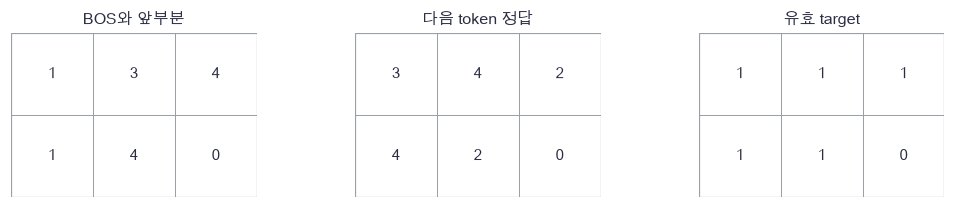

In [3]:
plot_decoder_contract(contract_inputs,contract_targets,contract_valid)

🔍 **확인** · 두 번째 행의 마지막0은 문장이 아닙니다. 모델의 입력에는 정답 앞부분이 있지만 attention이 미래 입력을 볼 수 있으면 바로 다음 정답을 훔쳐볼 수 있습니다. 다음 절에서 그 경로를 막습니다.

In [4]:
def language_batch(documents, pad=0, bos=1, eos=2):
    """정수 문서 목록을 BOS 입력·EOS 타깃으로 이동하고 오른쪽 PAD를 채웁니다."""
    length = max(len(document)+1 for document in documents)
    ids = np.full((len(documents),length),pad,dtype=int)
    targets = np.full_like(ids,pad)
    valid = np.zeros_like(ids,dtype=bool)
    for index,document in enumerate(documents):
        count = len(document)+1
        ids[index,:count] = [bos]+list(document)
        targets[index,:count] = list(document)+[eos]
        valid[index,:count] = True
    return ids,targets,valid

In [5]:
mini_batch=language_batch([[3,4],[4]])
np.testing.assert_array_equal(mini_batch[0],contract_inputs)  # 검산: 입력 shift
np.testing.assert_array_equal(mini_batch[1],contract_targets)  # 검산: target shift
np.testing.assert_array_equal(mini_batch[2],contract_valid)  # 검산: EOS 포함 유효 위치
assert language_batch([[]])[1][0,0]==2, '빈 문서의 첫 정답은EOS입니다'
print('문서별 shift·padding·빈 문서 검산 통과')

문서별 shift·padding·빈 문서 검산 통과


### ✏️ 연습 1 · 유효 토큰 수를 세기

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

본문 길이 lengths에 문서별 EOS 하나를 포함한 total을 채우세요.

In [6]:
def exercise_targets(lengths):
    """유효 토큰 수를 세기의 계산을 완성합니다."""
    ### 구현할 내용: 본문 길이 lengths에 문서별 EOS 하나를 포함한 total을 채우세요.
    raise NotImplementedError
    return total

In [7]:
def check_targets(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate(np.array([2,1,0]))==6, 'EOS를 포함하면3+2+1=6입니다'
    print("연습 1 통과")

run_check(check_targets, exercise_targets, hint="유효 토큰 수를 세기의 수식과 축을 확인하세요.")

☐ exercise_targets: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 유효 토큰 수를 세기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.sum(lengths + 1)
```

</details>

## 🔑 2. 미래와 padding을 동시에 막는 attention

**이 절에서 가져갈 것:** 허용한 key에서만 정규화하며, 전부 막힌 query 행은 확률과 미분을 0으로 정의합니다.

현재 `gold `까지 읽었다면 뒤의 `grape`나 마지막 `gold`는 아직 볼 수 없습니다. 하지만 앞의 `g`와 `o`는 볼 수 있습니다.

$$Q=XW_Q,\ K=XW_K,\ V=XW_V,\quad A=QK^T/\sqrt D,\quad
P_{ij}=\operatorname{softmax}_{j\in\mathcal A_i}(A_{ij}),\quad Y=(PV)W_O.$$

Q/K/V는 `(N,T,D)`, 점수와 확률은 `(N,T,T)`입니다. 허용 조건은 `query_valid & key_valid & (key_position<=query_position)`입니다. 자기 위치는 허용합니다. 전부 막힌 행은 분모가0이므로 별도로 P=0을 반환합니다. 막힌 칸에 큰 점수가 있어도 허용한 칸의 최대값만 빼야 안정적입니다.

$G_A=P\odot(G_P-\sum_jP_jG_{P,j})$이고 $G_Q=G_AK/\sqrt D$, $G_K=G_A^TQ/\sqrt D$, $G_V=P^TG_{PV}$입니다. Q/K/V 세 입력 기여를 모두 합합니다.

> **코드** · `np.tril`은 대각선 아래를 남깁니다. `swapaxes(-1,-2)`는 배치 축을 둔 채 마지막 두 축만 전치합니다. `np.where`는 허용 여부로 −∞를 놓고, `np.divide(...,where=total>0,out=zeros)`는 전부 막힌 행의0/0을 피합니다.

In [8]:
attention_x=np.array([[1.,0.],[0.,1.],[1.,1.],[9.,9.]])
attention_valid=np.array([1,1,1,0],dtype=bool)
attention_scores=attention_x@attention_x.T/np.sqrt(2)
attention_allowed=np.tril(np.ones((4,4),dtype=bool))&attention_valid[:,None]&attention_valid[None,:]
masked_scores=np.where(attention_allowed,attention_scores,-np.inf)
masked_max=np.max(masked_scores,axis=-1,keepdims=True)
masked_max=np.where(np.isfinite(masked_max),masked_max,0)
attention_exp=np.exp(masked_scores-masked_max)
attention_denominator=attention_exp.sum(axis=-1,keepdims=True)
attention_probabilities=np.divide(attention_exp,attention_denominator,out=np.zeros_like(attention_exp),where=attention_denominator>0)

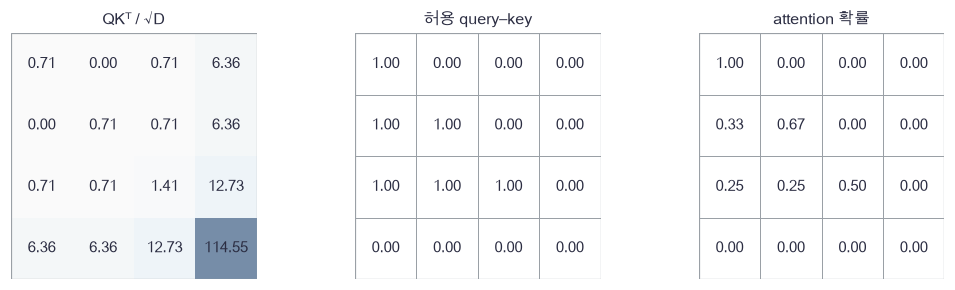

In [9]:
plot_causal_attention(attention_scores,attention_allowed,attention_probabilities)

🔍 **확인** · 마지막 padding 행은 전부0이고 앞의 행은 허용된 칸의 합이1입니다. 정답을 모르는 token 자리까지 입력으로 채우고 mask로 막는 방식과, 생성할 때 prefix만 넣는 방식이 같은 과거 계산을 만들어야 합니다.

In [10]:
def masked_softmax(scores, allowed):
    """마지막 key 축에서 허용한 점수만 정규화합니다. 전부 막힌 행은0입니다."""
    masked = np.where(allowed, scores, -np.inf)
    maximum = masked.max(axis=-1, keepdims=True)
    maximum = np.where(np.isfinite(maximum), maximum, 0.)
    exponential = np.exp(masked - maximum)
    total = exponential.sum(axis=-1, keepdims=True)
    return np.divide(exponential, total, out=np.zeros_like(exponential), where=total > 0)

In [11]:
def attention_forward(x, valid, p, causal=True):
    """한 head self-attention. x:(N,T,D), valid:(N,T); query/key padding을 모두 막습니다."""
    q, k, v = x @ p['Wq'], x @ p['Wk'], x @ p['Wv']
    scores = q @ k.swapaxes(-1,-2) / np.sqrt(x.shape[-1])
    allowed = valid[:,:,None] & valid[:,None,:]
    if causal:
        allowed = allowed & np.tril(np.ones((x.shape[1],x.shape[1]),dtype=bool))[None,:,:]
    probabilities = masked_softmax(scores, allowed)
    mixed = probabilities @ v
    return mixed @ p['Wo'], (x,q,k,v,probabilities,mixed)

In [12]:
def attention_backward(upstream, cache, p):
    """attention의 값 경로와 Q/K 점수 경로를 모두 누적합니다."""
    x,q,k,v,probabilities,mixed = cache
    width = x.shape[-1]
    delta = upstream @ p['Wo'].T
    dp = delta @ v.swapaxes(-1,-2)
    dv = probabilities.swapaxes(-1,-2) @ delta
    ds = probabilities * (dp - np.sum(dp * probabilities, axis=-1, keepdims=True))
    dq = (ds @ k) / np.sqrt(width)
    dk = (ds.swapaxes(-1,-2) @ q) / np.sqrt(width)
    flat = x.reshape(-1,width)
    gradients = {'Wo': mixed.reshape(-1,width).T @ upstream.reshape(-1,width),
                 'Wq': flat.T @ dq.reshape(-1,width), 'Wk': flat.T @ dk.reshape(-1,width),
                 'Wv': flat.T @ dv.reshape(-1,width)}
    dx = dq @ p['Wq'].T + dk @ p['Wk'].T + dv @ p['Wv'].T
    return dx, gradients

In [13]:
# 쓰는 것: attention_allowed, attention_probabilities, attention_scores (앞 절의 정의·실행 셀)
np.testing.assert_allclose(masked_softmax(attention_scores,attention_allowed),attention_probabilities)  # 검산: 직접 계산 = 함수
changed_scores=attention_scores.copy()
changed_scores[~attention_allowed]=1000
np.testing.assert_allclose(masked_softmax(changed_scores,attention_allowed),attention_probabilities)  # 검산: 차단 점수는 무관
assert np.all(attention_probabilities[~attention_allowed]==0), '막힌 칸 확률은 정확히0입니다'
print('미래·padding·전부 차단 행·극단 차단 점수 검산 통과')

미래·padding·전부 차단 행·극단 차단 점수 검산 통과


### ✏️ 연습 2 · causal 허용 행렬

position에서 key가 query보다 늦지 않은 allowed를 채우세요.

In [14]:
def exercise_causal(position):
    """causal 허용 행렬의 계산을 완성합니다."""
    ### 구현할 내용: position에서 key가 query보다 늦지 않은 allowed를 채우세요.
    raise NotImplementedError
    return allowed

In [15]:
def check_causal(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_array_equal(candidate(np.arange(3)),[[1,0,0],[1,1,0],[1,1,1]])  # 검산: 자기 위치 포함 하삼각
    print("연습 2 통과")

run_check(check_causal, exercise_causal, hint="causal 허용 행렬의 수식과 축을 확인하세요.")

☐ exercise_causal: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: causal 허용 행렬의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
allowed = position[None,:] <= position[:,None]
```

</details>

## 🔑 3. 정규화·FFN·잔차의 모든 경로를 미분합니다

**이 절에서 가져갈 것:** 잔차의 직접 경로를 보존하고 shared embedding의 출력 경로까지 정확히 누적합니다.

각 문자의 D개 특성 값 크기가 다를 때 token별 LayerNorm으로 가지의 입력을 정리합니다. 원래 입력은 잔차로 그대로 이어 둡니다. 작은 숫자 행에서 먼저 `X+FFN(LN(X))`를 계산합니다.

$$\hat X=(X-\mu)/\sqrt{v+\epsilon},\quad LN(X)=\gamma\odot\hat X+\beta,\quad
FFN(U)=\tanh(UW_1+c_1)W_2+c_2.$$

평균·분산은 마지막 D축에서 구합니다. $W_1:(D,F)$, $c_1:(F,)$, $W_2:(F,D)$, $c_2:(D,)$입니다. epsilon 때문에 정규화 분산이 정확히1일 필요는 없습니다.

상류 G에 $B=G\odot\gamma$라 두면 $G_X=(B-mean(B)-\hat X mean(B\hat X))/\sqrt{v+\epsilon}$입니다. affine γ/β는 N,T축의 기여를 합합니다. 잔차 $R=X+F(X)$의 미분은 $G_R$와 F를 거친 기여의 합입니다.

> **용어** · **tied head**는 출력 행렬을 별도로 두지 않고 Eᵀ를 사용하는 방식입니다. E에는 입력 행 선택의 미분과 출력 head의 미분이 모두 옵니다. 주 실험은 untied이며 두 방식 모두 수치검산합니다.
>
> **코드** · `axis=-1,keepdims=True`는 마지막 특성축만 줄이고 크기1을 유지합니다. `np.add.at`은 반복 token ID의 미분을 누적합니다. 사전 `{name:zeros_like(value) for ...}`는 파라미터별 같은 모양의 빈 미분 배열입니다.

In [16]:
residual_x=np.array([[1.,2.,4.],[2.,0.,-1.]])
residual_centered=residual_x-residual_x.mean(axis=-1,keepdims=True)
residual_normalized=residual_centered/np.sqrt(np.mean(residual_centered**2,axis=-1,keepdims=True)+1e-5)
residual_output=residual_x+np.tanh(residual_normalized*.5)*.4

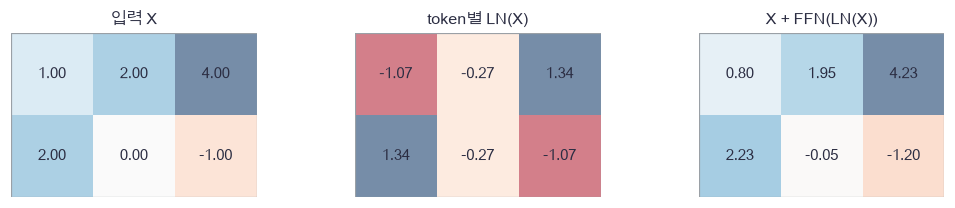

In [17]:
plot_residual_block(residual_x,residual_normalized,residual_output)

🔍 **확인** · 가운데 행들은 각 token 안에서 중심화되었습니다. 오른쪽은 정규화 결과 자체가 아니라 원래 행에 비선형 가지를 더한 값입니다. 아래에는 LN, 초기화, 한 block, 전체 embedding 경로를 각각 독립 함수 셀로 둡니다. 주 실험 폭D=12·FFN폭F=24·최대위치32입니다.

In [18]:
def layernorm_forward(x, gamma, beta, epsilon=1e-5):
    """각 token의 마지막 D축을 정규화하고 affine 변환합니다."""
    centered = x - x.mean(axis=-1, keepdims=True)
    inverse = 1 / np.sqrt(np.mean(centered**2, axis=-1, keepdims=True) + epsilon)
    normalized = centered * inverse
    return normalized * gamma + beta, (normalized, inverse, gamma)

In [19]:
def layernorm_backward(upstream, cache):
    """epsilon을 포함한 LayerNorm의 입력·gamma·beta 미분을 반환합니다."""
    normalized, inverse, gamma = cache
    weighted = upstream * gamma
    dx = inverse * (weighted - weighted.mean(axis=-1, keepdims=True)
                    - normalized * (weighted * normalized).mean(axis=-1, keepdims=True))
    axes = tuple(range(upstream.ndim - 1))
    return dx, np.sum(upstream * normalized, axis=axes), np.sum(upstream, axis=axes)

In [20]:
def init_decoder(vocabulary_size, width=12, hidden=24, max_length=32, seed=45, tied=False):
    """한 pre-LN decoder block과 최종 LN·head를 만듭니다. 모든 배열은 float64입니다."""
    rng = np.random.default_rng(seed)
    p = {'E': rng.normal(0,.15,(vocabulary_size,width)),
         'P': rng.normal(0,.08,(max_length,width))}
    for layer in ['1','2','f']:
        p['g'+layer] = np.ones(width)
        p['b'+layer] = np.zeros(width)
    for name in ['Wq','Wk','Wv','Wo']:
        p[name] = rng.normal(0,.25/np.sqrt(width),(width,width))
    p['W1'] = rng.normal(0,.5/np.sqrt(width),(width,hidden))
    p['c1'] = np.zeros(hidden)
    p['W2'] = rng.normal(0,.5/np.sqrt(hidden),(hidden,width))
    p['c2'] = np.zeros(width)
    if not tied:
        p['head'] = rng.normal(0,.3/np.sqrt(width),(width,vocabulary_size))
    p['bias'] = np.zeros(vocabulary_size)
    return p

In [21]:
def decoder_from_embeddings(x, valid, p, tied=False, causal=True):
    """연속 embedding 입력에서 LN→attention→잔차→LN→FFN→잔차→LN→head입니다."""
    # 쓰는 것: attention_forward (앞 절의 정의·실행 셀)
    first, cache1 = layernorm_forward(x,p['g1'],p['b1'])
    attended, attention_cache = attention_forward(first,valid,p,causal)
    residual = x + attended
    second, cache2 = layernorm_forward(residual,p['g2'],p['b2'])
    activation = np.tanh(second @ p['W1'] + p['c1'])
    hidden = residual + activation @ p['W2'] + p['c2']
    final, cachef = layernorm_forward(hidden,p['gf'],p['bf'])
    head = p['E'].T if tied else p['head']
    logits = final @ head + p['bias']
    return logits,(cache1,attention_cache,cache2,second,activation,cachef,final)

In [22]:
def decoder_feature_backward(dlogits, cache, p, tied=False):
    """연속 입력과 모든 block/head 배열을 미분합니다. tied이면 출력 E 경로도 더합니다."""
    # 쓰는 것: attention_backward (앞 절의 정의·실행 셀)
    # 1) head와 최종 정규화를 거슬러 갑니다.
    cache1,attention_cache,cache2,second,activation,cachef,final = cache
    width = final.shape[-1]
    gradients = {name:np.zeros_like(value) for name,value in p.items()}
    head_gradient = final.reshape(-1,width).T @ dlogits.reshape(-1,dlogits.shape[-1])
    if tied:
        gradients['E'] += head_gradient.T
        delta = dlogits @ p['E']
    else:
        gradients['head'] = head_gradient
        delta = dlogits @ p['head'].T
    gradients['bias'] = dlogits.sum(axis=(0,1))
    dh,gradients['gf'],gradients['bf'] = layernorm_backward(delta,cachef)
    # 2) FFN 경로와 직접 잔차 경로를 합칩니다.
    gradients['W2'] = activation.reshape(-1,activation.shape[-1]).T @ dh.reshape(-1,width)
    gradients['c2'] = dh.sum(axis=(0,1))
    da = (dh @ p['W2'].T) * (1-activation**2)
    gradients['W1'] = second.reshape(-1,width).T @ da.reshape(-1,da.shape[-1])
    gradients['c1'] = da.sum(axis=(0,1))
    dr,gradients['g2'],gradients['b2'] = layernorm_backward(da @ p['W1'].T,cache2)
    dr += dh
    # 3) attention의 모든 경로와 첫 잔차를 합칩니다.
    du,attention_gradients = attention_backward(dr,attention_cache,p)
    gradients.update(attention_gradients)
    dx,gradients['g1'],gradients['b1'] = layernorm_backward(du,cache1)
    return dx + dr, gradients

In [23]:
def decoder_forward(ids, valid, p, tied=False, causal=True):
    """정수 ID→학습 embedding+절대 위치→decoder. PAD 위치의 입력은0으로 만듭니다."""
    assert ids.shape[1] <= len(p['P']), '학습 위치 표의 최대 길이를 넘을 수 없습니다'
    embedded = (p['E'][ids] + p['P'][:ids.shape[1]]) * valid[:,:,None]
    logits,cache = decoder_from_embeddings(embedded,valid,p,tied,causal)
    return logits,(ids,valid,cache)

In [24]:
def decoder_backward(dlogits, full_cache, p, tied=False):
    """선택된 embedding 반복행과 배치가 공유하는 위치행까지 누적합니다."""
    ids,valid,cache = full_cache
    dx,gradients = decoder_feature_backward(dlogits,cache,p,tied)
    dx *= valid[:,:,None]
    np.add.at(gradients['E'],ids.ravel(),dx.reshape(-1,dx.shape[-1]))
    gradients['P'][:ids.shape[1]] += dx.sum(axis=0)
    return gradients,dx

In [25]:
def token_cross_entropy(logits, targets, weights):
    """선택한 target만 가중 평균합니다. logprob 전체와 정확한 dlogits를 반환합니다."""
    shifted = logits - logits.max(axis=-1,keepdims=True)
    logprob = shifted - np.log(np.exp(shifted).sum(axis=-1,keepdims=True))
    denominator = weights.sum()
    assert denominator > 0, '손실에 포함할 target이 적어도 하나 필요합니다'
    assert np.all(weights >= 0), '손실 가중치는 음수가 아니어야 합니다'
    rows = np.arange(targets.size)
    selected = logprob.reshape(-1,logits.shape[-1])[rows,targets.ravel()].reshape(targets.shape)
    loss = -np.sum(selected * weights) / denominator
    delta = np.exp(logprob).reshape(-1,logits.shape[-1])
    delta[rows,targets.ravel()] -= 1
    delta *= weights.ravel()[:,None] / denominator
    return float(loss),delta.reshape(logits.shape),logprob

In [26]:
def decoder_loss(ids, targets, valid, p, tied=False, weights=None, causal=True):
    """모델 전체와 선택 target CE를 연결합니다. 입력 유효 mask와 loss mask를 구분합니다."""
    logits,cache = decoder_forward(ids,valid,p,tied,causal)
    actual_weights = valid if weights is None else weights * valid
    loss,delta,logprob = token_cross_entropy(logits,targets,actual_weights)
    gradients,dx = decoder_backward(delta,cache,p,tied)
    return loss,gradients,logprob,dx

📎 **전체 검산 범위** · D=3,F=4,V=5,Tmax=4의 작은 모델로 **모든 파라미터 원소**를 중심차분합니다. untied는132개, tied는117개입니다. 별도로 `(N,T,D)` 연속 embedding 입력을 미분합니다. 이것은 token 정수 ID의 미분이 아닙니다. tied에서는 PAD로만 쓰인 E행도 출력 어휘 경로의 미분을 받을 수 있습니다.

> **코드** · `numerical_gradient(objective,array)`는 배열 원소를 ±h로 바꾸고 원상복구합니다. 중첩된 `objective()`는 현재 배열을 읽는 스칼라 함수입니다. `parameters.items()`는 이름·배열 쌍을 순회합니다.

In [27]:
def check_decoder_gradients():
    """tied/untied의 모든 배열과 연속 embedding 입력을 전수 중심차분합니다."""
    # 쓰는 것: decoder_feature_backward, decoder_from_embeddings, init_decoder (앞 절의 정의·실행 셀)
    errors=[]
    for tied in [False,True]:
        p=init_decoder(5,width=3,hidden=4,max_length=4,seed=4501,tied=tied)
        ids=np.array([[1,3,3],[1,4,0]])
        targets=np.array([[3,3,2],[4,2,0]])
        valid=ids!=0
        loss,gradients,_,_=decoder_loss(ids,targets,valid,p,tied)
        def objective():
            """고정 target·mask에서 전체 decoder CE를 계산합니다."""
            return decoder_loss(ids,targets,valid,p,tied)[0]
        for name,value in p.items():
            numeric=numerical_gradient(objective,value)
            np.testing.assert_allclose(gradients[name],numeric,atol=3e-7,rtol=2e-4)  # 검산: 모든 파라미터 손미분 = 중심차분
            errors.append(np.max(np.abs(gradients[name]-numeric)))
        x=np.random.default_rng(4503).normal(size=(2,3,3))
        logits,cache=decoder_from_embeddings(x,valid,p,tied)
        _,delta,_=token_cross_entropy(logits,targets,valid)
        dx,_=decoder_feature_backward(delta,cache,p,tied)
        def continuous_objective():
            """정수 ID 대신 연속 특성 입력의 목적을 계산합니다."""
            return token_cross_entropy(decoder_from_embeddings(x,valid,p,tied)[0],targets,valid)[0]
        numeric=numerical_gradient(continuous_objective,x)
        np.testing.assert_allclose(dx,numeric,atol=3e-7,rtol=2e-4)  # 검산: 연속 embedding 입력의 전체 미분
        errors.append(np.max(np.abs(dx-numeric)))
    return max(errors)

In [28]:
print('tied/untied 전체 파라미터·연속 입력 최대 절대오차:',check_decoder_gradients())

tied/untied 전체 파라미터·연속 입력 최대 절대오차: 8.009586327517582e-10


### ✏️ 연습 3 · tied embedding의 두 기여

입력 행 선택 기여 input_gradient와 head 미분 head_gradient로 dE를 완성하세요.

In [29]:
def exercise_tied(input_gradient, head_gradient):
    """tied embedding의 두 기여의 계산을 완성합니다."""
    ### 구현할 내용: 입력 행 선택 기여 input_gradient와 head 미분 head_gradient로 dE를 완성하세요.
    raise NotImplementedError
    return dE

In [30]:
def check_tied(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.ones((3,2)),np.full((2,3),2.)),np.full((3,2),3.))  # 검산: 입력+출력 공유 기여
    print("연습 3 통과")

run_check(check_tied, exercise_tied, hint="tied embedding의 두 기여의 수식과 축을 확인하세요.")

☐ exercise_tied: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: tied embedding의 두 기여의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dE = input_gradient + head_gradient.T
```

</details>

## 🔑 4. 전체 decoder를 고정 예산으로 실제 학습합니다

**이 절에서 가져갈 것:** 선택된 정답의 CE가 모든 층으로 돌아가며, 독립 자료의 NLL을 따로 기록합니다.

과일 문장에 마지막 색을 다시 쓰는 `gold grape is gold.`를 사용합니다. 정답 확률이 0.5라면 손실은 $-\log0.5$입니다. 정답 외의 모든 어휘 점수에도 softmax 미분이 생깁니다. 유효 token 수로 나눈 이 신호가 앞 절의 모든 backward로 전해집니다.

$$G_S=m\odot(P-\mathrm{onehot}(y))/M,\qquad M=\sum m.$$

예시 그림의 세 위치는 모두 유효합니다. 실제 배치에서는 padding 위치의 미분이0입니다. 학습은 색4개×과일4개의 **고유 문장16개**를 seed4502로 나눠 train12/valid2/test2로 사용합니다. 문자 어휘는 이 예제의 명시된 문법 문자 집합으로 미리 고정합니다. 평가 문장 빈도나 정답을 이용해 어휘를 학습하지 않습니다.

300회·배치8·seed45·Adam 학습률.01, β₁=.9, β₂=.999, ε=1e−8을 고정합니다. valid는100회마다 기록하지만 checkpoint나 설정을 고르지 않습니다. 두 문장짜리 test의 결과는 제한적인 관찰입니다.

> **용어** · **NLL**은 정답의 음의 로그 확률입니다. **full backward**는 head만 고치는 것이 아니라 embedding·위치·정규화·attention·FFN 전체를 미분한다는 뜻입니다.
>
> **코드** · `np.arange(N)`는 행 번호, `delta[rows,target]-=1`은 정답 칸의 one-hot을 뺍니다. `rng.integers`는 train 문서 번호를 복원추출합니다. `*batch`는 입력·정답·mask 세 배열을 인자로 풉니다.

In [31]:
loss_probabilities=np.array([[.5,.3,.2],[.1,.7,.2],[.2,.3,.5]])
loss_targets=np.array([0,1,2])
loss_values=-np.log(loss_probabilities[np.arange(3),loss_targets])
loss_gradients=loss_probabilities.copy()
loss_gradients[np.arange(3),loss_targets]-=1
loss_gradients/=3

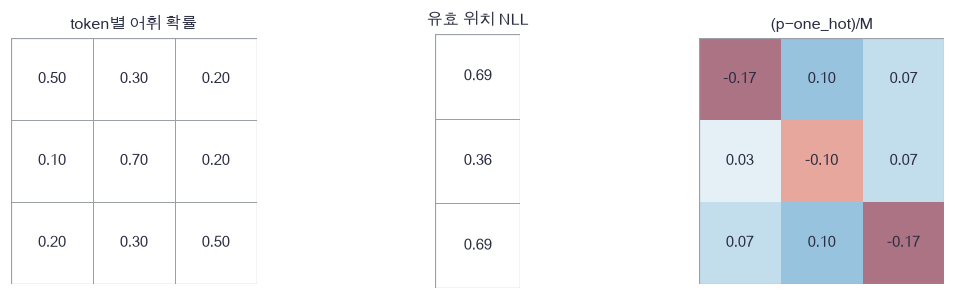

In [32]:
plot_loss_path(loss_probabilities,loss_values,loss_gradients)

🔍 **확인** · 정답 칸은 음의 미분으로 점수를 올리는 방향, 나머지는 양의 미분으로 점수를 내리는 방향입니다. 각 행의 미분 합은0입니다. Adam은 $m_t=.9m_{t-1}+.1g_t$, $v_t=.999v_{t-1}+.001g_t^2$를 편향 보정한 뒤 파라미터를 갱신합니다. tokenizer 선택·손실·optimizer는 서로 다른 규칙입니다.

In [33]:
def adam_state(p):
    """모든 학습 배열에 독립인 Adam 상태를 만듭니다."""
    return {'m':{name:np.zeros_like(value) for name,value in p.items()},
            'v':{name:np.zeros_like(value) for name,value in p.items()},'t':0}

In [34]:
def adam_update(p, gradients, state, learning_rate=.01):
    """Adam의 모멘트와 편향 보정으로 지정된 배열만 갱신합니다."""
    state['t'] += 1
    for name in gradients:
        state['m'][name] = .9*state['m'][name] + .1*gradients[name]
        state['v'][name] = .999*state['v'][name] + .001*gradients[name]**2
        first = state['m'][name]/(1-.9**state['t'])
        second = state['v'][name]/(1-.999**state['t'])
        p[name] -= learning_rate*first/(np.sqrt(second)+1e-8)

In [35]:
def train_decoder(train_batch, valid_batch, vocabulary_size, seed=45, steps=300, tied=False):
    """고정 300회 미니배치 Adam 후 반환합니다. valid는 기록만 하고 선택하지 않습니다."""
    # 쓰는 것: decoder_loss, init_decoder (앞 절의 정의·실행 셀)
    p = init_decoder(vocabulary_size,seed=seed,tied=tied)
    state = adam_state(p)
    rng = np.random.default_rng(seed+100)
    history = []
    for step in range(steps+1):
        if step % 100 == 0:
            train_loss = decoder_loss(*train_batch,p,tied)[0]
            valid_loss = decoder_loss(*valid_batch,p,tied)[0]
            history.append([step,train_loss,valid_loss])
        if step == steps:
            break
        index = rng.integers(0,len(train_batch[0]),size=8)
        batch = tuple(array[index] for array in train_batch)
        _,gradients,_,_ = decoder_loss(*batch,p,tied)
        adam_update(p,gradients,state)
    return p,np.asarray(history)

In [36]:
# 쓰는 것: language_batch (앞 절의 정의·실행 셀)
colors=['red','green','gold','blue']
fruits=['apple','pear','plum','grape']
all_sentences=[f'{color} {fruit} is {color}.' for color in colors for fruit in fruits]
character_alphabet=sorted(set('red green gold blue apple pear plum grape is.'))
character_to_id={character:index+3 for index,character in enumerate(character_alphabet)}
id_to_character={value:key for key,value in character_to_id.items()}
order=np.random.default_rng(4502).permutation(16)
train_texts=[all_sentences[i] for i in order[:12]]
valid_texts=[all_sentences[i] for i in order[12:14]]
test_texts=[all_sentences[i] for i in order[14:]]
train_batch=language_batch([[character_to_id[c] for c in text] for text in train_texts])
valid_batch=language_batch([[character_to_id[c] for c in text] for text in valid_texts])
test_batch=language_batch([[character_to_id[c] for c in text] for text in test_texts])
assert not set(train_texts)&set(test_texts), 'train/test의 고유 문장은 겹치면 안 됩니다'
assert not set(valid_texts)&set(test_texts), 'valid/test도 겹치면 안 됩니다'
print('분할:',len(train_texts),len(valid_texts),len(test_texts),'· 문자 어휘+특수:',len(character_to_id)+3)

분할: 12 2 2 · 문자 어휘+특수: 19


In [37]:
trained,history=train_decoder(train_batch,valid_batch,len(character_to_id)+3)
print('학습한 파라미터 수:',sum(value.size for value in trained.values()))
assert np.isfinite(history).all(), '모든 기록 손실은 유한해야 합니다'

학습한 파라미터 수: 2119


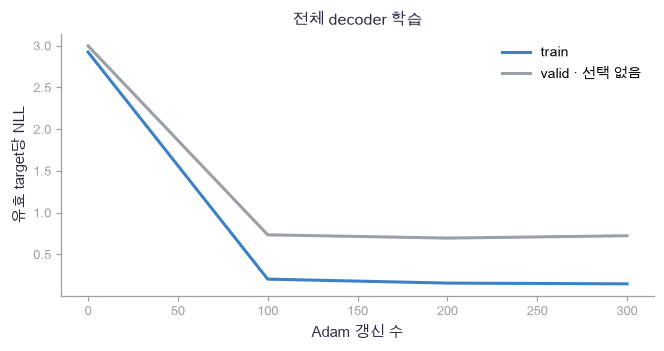

In [38]:
plot_decoder_learning(history)

In [39]:
def check_decoder_masks(p):
    """미래 token·PAD 값·추가 PAD 폭·전부 PAD의 forward/backward 경계를 확인합니다."""
    # 쓰는 것: decoder_forward, decoder_loss (앞 절의 정의·실행 셀)
    ids=np.array([[1,3,4,3,0]])
    valid=ids!=0
    logits,_=decoder_forward(ids,valid,p)
    changed=ids.copy()
    changed[0,3]=5
    changed_logits,_=decoder_forward(changed,valid,p)
    np.testing.assert_allclose(logits[:,:3],changed_logits[:,:3],atol=1e-12)  # 검산: 미래 token 변경에 과거 logits 불변
    changed=ids.copy()
    changed[0,-1]=6
    np.testing.assert_allclose(decoder_forward(changed,valid,p)[0],logits,atol=1e-12)  # 검산: PAD 값 변경 불변
    wide=np.pad(ids,((0,0),(0,2)))
    wide_valid=np.pad(valid,((0,0),(0,2)))
    np.testing.assert_allclose(decoder_forward(wide,wide_valid,p)[0][:,:5],logits,atol=1e-12)  # 검산: 오른쪽 PAD 폭 변경 불변
    all_pad=np.zeros((1,3),dtype=int)
    empty_logits,_=decoder_forward(all_pad,all_pad.astype(bool),p)
    assert np.isfinite(empty_logits).all(), '전부 PAD forward도 유한해야 합니다'
    rejected=False
    try:
        decoder_loss(all_pad,all_pad,all_pad.astype(bool),p)
    except AssertionError:
        rejected=True
    assert rejected, '유효 정답0개인 평균 손실은 명시적으로 거부해야 합니다'
    print('미래·PAD 값·폭·빈 평균 경계 검산 통과')

In [40]:
check_decoder_masks(trained)

미래·PAD 값·폭·빈 평균 경계 검산 통과


### ✏️ 연습 4 · CE 점수 미분의 합

확률 probabilities와 정답 target에서 gradient를 완성하세요.

In [41]:
def exercise_ce(probabilities, target):
    """CE 점수 미분의 합의 계산을 완성합니다."""
    gradient = probabilities.copy()
    ### 구현할 내용: 확률 probabilities와 정답 target에서 gradient를 완성하세요.
    raise NotImplementedError
    return gradient

In [42]:
def check_ce(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    actual=candidate(np.array([[.2,.8],[.6,.4]]),np.array([1,0]))
    np.testing.assert_allclose(actual,[[.1,-.1],[-.2,.2]])  # 검산: p−one_hot의 배치 평균
    print("연습 4 통과")

run_check(check_ce, exercise_ce, hint="CE 점수 미분의 합의 수식과 축을 확인하세요.")

☐ exercise_ce: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: CE 점수 미분의 합의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient[np.arange(len(target)), target] -= 1
gradient /= len(target)
```

</details>

## 🔑 5. held-out NLL과 정답 없는 생성을 구분합니다

**이 절에서 가져갈 것:** teacher forcing 점수와 prefix 이후의 자유 생성 결과를 함께 보고 EOS·길이 상한을 명시합니다.

`gold`까지만 주고 이후를 생성하면 모델은 과일 이름도 직접 골라야 합니다. 이때 실제 평가 문장의 나머지를 입력으로 주지 않습니다. 반면 token NLL에서는 매 위치에 정답 앞부분을 줍니다. 두 절차가 다른 정보를 받는다는 점이 핵심입니다.

생성은 마지막 위치의 $p(u_{t+1}\mid u_{\le t})$를 구하고 token을 하나 붙인 뒤 반복합니다. 여기서는 argmax를 고르는 greedy이며 PAD/BOS 출력은 금지합니다. EOS가 나오거나 생성 상한 또는 위치 표32에 도달하면 멈춥니다. 위치 표를 넘어선 길이에 자동으로 같은 의미를 부여하지 않습니다.

아래 그림은 실제 학습 모형에 prefix를 넣어 얻은 마지막 위치의 상위 다섯 확률입니다. 그림에 표시하지 않은 어휘의 확률도 존재합니다.

> **코드** · `np.argsort(probabilities)[-5:]`는 상위 다섯 위치를 고릅니다. `dict.get(id,'')`는 제어 ID를 출력 문자에서 제외합니다. 생성 결과의 EOS 포함 여부는 별도 Boolean으로 반환합니다.

In [43]:
# 쓰는 것: character_to_id, decoder_forward, id_to_character, trained (앞 절의 정의·실행 셀)
prefix_text='gold'
prefix_ids=[1]+[character_to_id[c] for c in prefix_text]
prefix_array=np.array([prefix_ids])
prefix_logits,_=decoder_forward(prefix_array,np.ones_like(prefix_array,dtype=bool),trained)
prefix_scores=prefix_logits[0,-1]
prefix_prob=np.exp(prefix_scores-prefix_scores.max())
prefix_prob/=prefix_prob.sum()
shown=np.argsort(prefix_prob)[-5:]
shown_labels=[repr(id_to_character.get(int(i),['PAD','BOS','EOS'][i] if i<3 else '?')) for i in shown]
selected_scores=prefix_scores.copy()
selected_scores[[0,1]]=-np.inf
selected_id=int(np.argmax(selected_scores))

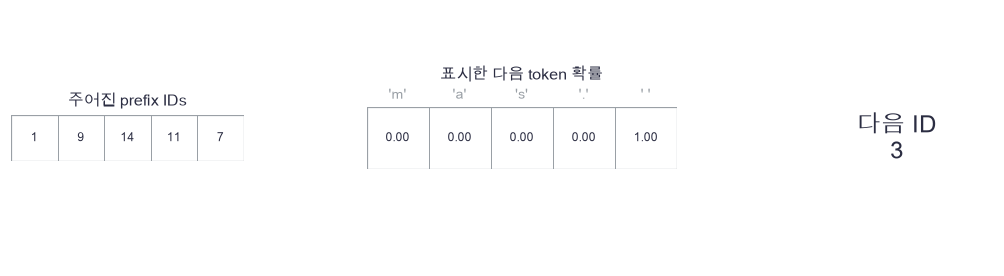

In [44]:
plot_next_token(prefix_ids,prefix_prob[shown],shown_labels,selected_id)

🔍 **확인** · 그림은 현재 prefix에서의 한 단계입니다. 최고 확률을 골랐다고 전체 문장 확률이 최대인 것은 아닙니다. 샘플링·temperature·top-k와 계산 재사용은46번에서 분리해 구현합니다.

In [45]:
def greedy_decode(prefix, p, eos=2, max_new_tokens=30, tied=False):
    """prefix를 유지하고 전체 문맥을 매번 재계산해 EOS 또는 길이 상한까지 생성합니다."""
    # 쓰는 것: decoder_forward (앞 절의 정의·실행 셀)
    tokens = list(prefix)
    assert len(tokens)>0, 'prefix에는 BOS 등 적어도 한 token이 필요합니다'
    for _ in range(max_new_tokens):
        if len(tokens) >= len(p['P']):
            break
        ids = np.array([tokens],dtype=int)
        logits,_ = decoder_forward(ids,np.ones_like(ids,dtype=bool),p,tied)
        scores = logits[0,-1].copy()
        scores[[0,1]] = -np.inf
        token = int(np.argmax(scores))
        tokens.append(token)
        if token==eos:
            break
    return tokens,bool(tokens[-1]==eos)

In [46]:
# 쓰는 것: character_to_id, decoder_loss, id_to_character, test_batch, test_texts, train_batch, train_texts, trained, valid_batch (앞 절의 정의·실행 셀)
for name,batch in [('train',train_batch),('valid',valid_batch),('test',test_batch)]:
    loss,_,logprob,_=decoder_loss(*batch,trained)
    prediction=np.argmax(logprob,axis=-1)
    accuracy=np.sum((prediction==batch[1])*batch[2])/batch[2].sum()
    print(name,'NLL',round(loss,4),'PPL',round(np.exp(loss),3),'teacher token accuracy',round(accuracy,3))
for name,texts in [('train',train_texts[:2]),('test',test_texts)]:
    for expected in texts:
        prefix=[1]+[character_to_id[c] for c in expected[:4]]
        result,terminated=greedy_decode(prefix,trained,max_new_tokens=26)
        generated=''.join(id_to_character.get(i,'') for i in result)
        print(name,'정답:',expected,'· 생성:',generated,'· EOS:',terminated,'· 전체일치:',terminated and generated==expected)

train NLL 0.1473 PPL 1.159 teacher token accuracy 0.909
valid NLL 0.723 PPL 2.061 teacher token accuracy 0.814
test NLL 1.014 PPL 2.757 teacher token accuracy 0.73
train 정답: gold grape is gold. · 생성: gold grape is gold. · EOS: True · 전체일치: True
train 정답: red grape is red. · 생성: red grape is red. · EOS: True · 전체일치: True
test 정답: gold pear is gold. · 생성: gold grape is gold. · EOS: True · 전체일치: False
test 정답: red apple is red. · 생성: red grape is red. · EOS: True · 전체일치: False


In [47]:
# 쓰는 것: trained (앞 절의 정의·실행 셀)
forced={name:value.copy() for name,value in trained.items()}
forced['head'][:]=0
forced['bias'][:]=-100
forced['bias'][2]=100
ended,ended_flag=greedy_decode([1],forced,max_new_tokens=4)
assert ended==[1,2], '즉시EOS이면 한 번 생성하고 멈춰야 합니다'
assert ended_flag, 'EOS 종료를 보고해야 합니다'
forced['bias'][2]=-100
forced['bias'][3]=100
unfinished,unfinished_flag=greedy_decode([1],forced,max_new_tokens=4)
assert len(unfinished)==5, '미종료이면 지정한4개만 추가해야 합니다'
assert not unfinished_flag, '상한 종료를 EOS 종료로 보고하면 안 됩니다'
print('즉시EOS·상한 미종료 경계 검산 통과')

즉시EOS·상한 미종료 경계 검산 통과


🔍 **확인** · 학습 문장을 잘 이어도 held-out 색–과일 조합에서 학습한 다른 문장을 이어 쓸 수 있습니다. 이 고정 실행에서는 그 차이를 출력 그대로 읽습니다. 정답 문장이 유일한 자연어 답이라고 가정한 평가는 아니며, 전체 일치는 이 합성 문법의 복원 진단입니다. test 두 문장만으로 일반 언어 능력을 평가하지 않습니다.

원리의 출처는 [Attention Is All You Need](https://arxiv.org/abs/1706.03762)와 [GPT의 생성 사전학습 원문](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf)입니다. 이 노트북의 작은 pre-LN·tanh 구조와 합성 문자 실험은 두 논문의 성능 재현이 아닙니다.

### ✏️ 연습 5 · token 정확도의 분모

prediction과 target이 같은 유효 위치의 비율 accuracy를 구하세요.

In [48]:
def exercise_accuracy(prediction, target, valid):
    """token 정확도의 분모의 계산을 완성합니다."""
    ### 구현할 내용: prediction과 target이 같은 유효 위치의 비율 accuracy를 구하세요.
    raise NotImplementedError
    return accuracy

In [49]:
def check_accuracy(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert np.isclose(candidate(np.array([1,3,9]),np.array([1,2,0]),np.array([1,1,0])),.5), 'PAD 오답은 분모에 넣지 않습니다'
    print("연습 5 통과")

run_check(check_accuracy, exercise_accuracy, hint="token 정확도의 분모의 수식과 축을 확인하세요.")

☐ exercise_accuracy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: token 정확도의 분모의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
accuracy = np.sum((prediction == target) * valid) / valid.sum()
```

</details>

## ✏️ 끝 연습 · A–D

앞의 계산을 작은 배열로 다시 연결합니다.

### ✏️ 연습 A · 미래를 막은 확률 합

probabilities에서 마지막 key 축의 합 row_sum을 구하세요.

In [50]:
def exercise_sum(probabilities):
    """미래를 막은 확률 합의 계산을 완성합니다."""
    ### 구현할 내용: probabilities에서 마지막 key 축의 합 row_sum을 구하세요.
    raise NotImplementedError
    return row_sum

In [51]:
def check_sum(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,0.],[.3,.7],[0.,0.]])),[1.,1.,0.])  # 검산: 유효 행1·전부 차단 행0
    print("연습 A 통과")

run_check(check_sum, exercise_sum, hint="미래를 막은 확률 합의 수식과 축을 확인하세요.")

☐ exercise_sum: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 미래를 막은 확률 합의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
row_sum = probabilities.sum(axis=-1)
```

</details>

### ✏️ 연습 B · 잔차 미분을 더하기

직접 기여 direct와 가지 기여 branch를 더한 dx를 구하세요.

In [52]:
def exercise_residual(direct, branch):
    """잔차 미분을 더하기의 계산을 완성합니다."""
    ### 구현할 내용: 직접 기여 direct와 가지 기여 branch를 더한 dx를 구하세요.
    raise NotImplementedError
    return dx

In [53]:
def check_residual(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,2.]),np.array([-.5,.2])),[.5,2.2])  # 검산: 두 경로 누적
    print("연습 B 통과")

run_check(check_residual, exercise_residual, hint="잔차 미분을 더하기의 수식과 축을 확인하세요.")

☐ exercise_residual: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 잔차 미분을 더하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dx = direct + branch
```

</details>

### ✏️ 연습 C · 배치가 공유한 위치 미분

dx:(N,T,D)를 배치 축에서 더한 dposition을 구하세요.

In [54]:
def exercise_position(dx):
    """배치가 공유한 위치 미분의 계산을 완성합니다."""
    ### 구현할 내용: dx:(N,T,D)를 배치 축에서 더한 dposition을 구하세요.
    raise NotImplementedError
    return dposition

In [55]:
def check_position(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    np.testing.assert_allclose(candidate(np.arange(8).reshape(2,2,2)),[[4,6],[8,10]])  # 검산: 위치별 두 배치 기여의 합
    print("연습 C 통과")

run_check(check_position, exercise_position, hint="배치가 공유한 위치 미분의 수식과 축을 확인하세요.")

☐ exercise_position: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 배치가 공유한 위치 미분의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dposition = dx.sum(axis=0)
```

</details>

### ✏️ 연습 D · 생성 종료 여부 확인하기

generated의 마지막 token이 eos인지 stopped를 구하세요.

In [56]:
def exercise_eos(generated, eos):
    """생성 종료 여부 확인하기의 계산을 완성합니다."""
    ### 구현할 내용: generated의 마지막 token이 eos인지 stopped를 구하세요.
    raise NotImplementedError
    return stopped

In [57]:
def check_eos(candidate):
    """작은 독립 손계산과 경계 입력으로 정답을 확인합니다."""
    assert candidate([3,2],2), '마지막EOS이면 종료입니다'
    assert not candidate([3,4],2), '상한으로 끝난 결과는EOS 종료가 아닙니다'
    assert not candidate([],2), '빈 결과도EOS 종료가 아닙니다'
    print("연습 D 통과")

run_check(check_eos, exercise_eos, hint="생성 종료 여부 확인하기의 수식과 축을 확인하세요.")

☐ exercise_eos: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 생성 종료 여부 확인하기의 수식과 축을 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
stopped = bool(generated and generated[-1] == eos)
```

</details>

## ✏️ 준비도 · 설명·수식·구현·변형 검산

- **설명:** teacher forcing에서 현재 입력은 허용하고 미래 입력은 금지하는 이유를 말할 수 있나요?
- **수식:** attention의 Q/K/V 세 기여와 잔차 직접 기여, LN 미분을 같은 입력으로 모을 수 있나요?
- **구현:** tied E의 입력·출력 미분을 합하고 작은 모델의 모든 파라미터와 연속 입력을 검산할 수 있나요?
- **변형 검산:** 미래 token·PAD 값·PAD 폭·tied 여부·즉시 EOS·미종료 상한을 바꾸어 어떤 값이 보존되는지 확인할 수 있나요?

46번에서는 학습된 가중치를 고정한 채 생성 분포를 바꾸는 규칙과 KV cache를 비교합니다. 학습 목적·생성 정책·추론 계산량을 같은 것으로 취급하지 않습니다.